<h1 style="color:red"># Auto MPG: Fuel Efficiency Analysis</h1>
**Client:** GreenDrive Motor  **Analyst:** Safeer Ullah Khan

---

<h2 style="color:orange">## Project Brief</h2>

**To:** Sara Malik, Head of Product Strategy, GreenDrive Motors  
**From:** Safeer Ullah Khan, Data Analyst  
**Subject:** Project brief: fuel efficiency analysis

Hi Sara,

Thank you for sharing the project details and the dataset. Below is my understanding of the project. Please confirm or let me know if anything needs to change before I begin.

### 1. Background
GreenDrive Motors is planning its next line of cars. Fuel prices are rising, customers care more about mileage, and new regulations are coming. GreenDrive wants to use historical data to decide how to design more fuel-efficient cars before investing in development.

### 2. Business objective
Find the main factors that drive a car's fuel efficiency (MPG), and build a model that can **predict the MPG of a new car design** from its specifications.

### 3. Key questions I will answer
1. Which car features affect fuel efficiency the most, ranked by importance?
2. How much MPG is lost as a car gets heavier? *(e.g., "every 500 kg more = X MPG less")*
3. How did fuel efficiency change between 1970 and 1982, and how fast did it improve?
4. Which region (USA, Europe or Japan) produced the most fuel-efficient cars, and why?
5. Do 4-cylinder cars always beat 6- and 8-cylinder cars, or do other factors such as weight explain the difference?
6. Can MPG be predicted accurately from a car's specifications?

### 4. Data
- **Source:** *Auto MPG.csv*, provided by GreenDrive
- **Size:** 398 cars, 9 columns, model years 1970–1982
- **Target variable:** `mpg` (miles per gallon)
- **Input features:** cylinders, displacement, horsepower, weight, acceleration, model year, origin and car name

### 5. Approach
1. **Data understanding:** review every column and its meaning.
2. **Data cleaning:** fix missing or invalid values and wrong data types. I will report every problem I find and how I handled it.
3. **Exploratory analysis:** use charts and statistics to answer questions 1–5.
4. **Feature preparation:** encode categories and create useful new variables.
5. **Modeling:** build and compare several prediction models against a simple baseline.
6. **Evaluation:** test accuracy on data the model has never seen.
7. **Reporting:** summarize findings and recommendations in plain language.

### 6. Success criteria
- The prediction model's average error on unseen data is **within ±3 MPG**.
- All six business questions are answered clearly, with supporting charts.
- Results are explained in non-technical language for the management team.

### 7. Deliverables
| Deliverable | Audience |
|---|---|
| Cleaned dataset (`auto_mpg_clean.csv`) | Technical team |
| Analysis notebook with full code and explanations | Technical team |
| Trained prediction model (saved file) | Technical team |
| Summary report (1–2 pages) with findings and recommendations | Management |

### 8. Timeline
| Day | Milestone | Update to client |
|---|---|---|
| Day 1 | Project brief + data understanding | Brief (this document) |
| Day 2 | Data cleaning | Data quality summary |
| Day 3–4 | Exploratory analysis | Key early insights |
| Day 5–6 | Modeling and evaluation | Model accuracy results |
| Day 7 | Final report and delivery | All deliverables |

### 9. Assumptions and limitations
- The data covers cars from 1970–1982, so absolute MPG values will be lower than for modern cars. The **relationships** between features (e.g., weight vs. MPG) should still be useful for guiding design decisions.
- With 398 cars, the dataset is small, so I will use cross-validation to make sure results are reliable.
- The analysis shows **associations** in the data. It does not prove that one feature directly causes a change in MPG.

### 10. Questions for the client
1. For the prediction model, which matters more: **highest accuracy**, or a model that is **easy to explain** (showing exactly how each feature affects MPG)?
2. Should results be in **US units** (MPG, pounds), as in the data, or in **metric units** (km/L, kg)?
3. Is there a specific type of car you're most interested in (e.g., compact, family or performance)?

I'll start on data understanding as soon as you confirm.

Best regards,  
[Your Name]  
Data Analyst

---
<h1 style="color:blue">## Phase 2: Data Understanding</h1>

*(Next step: to be completed after the client approves the brief.)*


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('Auto MPG.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


**In this dataset we found that there are different types of columns in term of datatypes 
3 floats
3 integers
3 objects

all columns have zero null values

notice: horsepower has object datatype but it has numeric values.**

In [3]:
df.describe(include=object)

,horsepower,car_name
count,398,398
unique,94,305
top,150,ford pinto
freq,22,6


In [4]:
df.shape

(398, 9)

In [5]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [6]:
df['horsepower'].unique()

<StringArray>
['130', '165', '150', '140', '198', '220', '215', '225', '190', '170', '160',
  '95',  '97',  '85',  '88',  '46',  '87',  '90', '113', '200', '210', '193',
   '?', '100', '105', '175', '153', '180', '110',  '72',  '86',  '70',  '76',
  '65',  '69',  '60',  '80',  '54', '208', '155', '112',  '92', '145', '137',
 '158', '167',  '94', '107', '230',  '49',  '75',  '91', '122',  '67',  '83',
  '78',  '52',  '61',  '93', '148', '129',  '96',  '71',  '98', '115',  '53',
  '81',  '79', '120', '152', '102', '108',  '68',  '58', '149',  '89',  '63',
  '48',  '66', '139', '103', '125', '133', '138', '135', '142',  '77',  '62',
 '132',  '84',  '64',  '74', '116',  '82']
Length: 94, dtype: str

** SO we find out that there is ? in the horsepower column which should be removed.

---
<h1 style="color:green">## Phase 3: Data Cleaning</h1>

In this phase I fix every data quality problem found during data understanding, and I record each one so it can be reported to the client.

I work on a copy of the data (`df_clean`), so the original `df` stays unchanged for comparison.

In [7]:
df_clean = df.copy()

### Step 1: Fix the `?` values in `horsepower`

`horsepower` is stored as text (`object`) because some rows contain `?` instead of a number. `?` is how this dataset marks a **missing value**.

First, let's see which cars have the problem.

In [8]:
df_clean[df_clean['horsepower'] == '?']

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,?,2046,19.0,71,1,ford pinto
126,21.0,6,200.0,?,2875,17.0,74,1,ford maverick
330,40.9,4,85.0,?,1835,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,?,2905,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,?,2320,15.8,81,2,renault 18i
374,23.0,4,151.0,?,3035,20.5,82,1,amc concord dl


Now I replace `?` with a real missing value (`NaN`) and convert the column to numbers. `errors='coerce'` turns anything that isn't a number into `NaN`.

In [9]:
df_clean['horsepower'] = df_clean['horsepower'].replace('?', np.nan)
df_clean['horsepower'] = pd.to_numeric(df_clean['horsepower'], errors='coerce')

print('Data type:', df_clean['horsepower'].dtype)
print('Missing values:', df_clean['horsepower'].isnull().sum())

Data type: float64
Missing values: 6


### Step 2: Fill the missing horsepower values

Only 6 of 398 cars (1.5%) are missing horsepower. There are two options:

| Option | Pro | Con |
|---|---|---|
| Delete the 6 rows | Simple | Loses 6 cars' worth of real `mpg`, `weight` and other data |
| Fill them with an estimate | Keeps all 398 cars | The filled values are estimates, not real values |

I'll **fill them in**. Using the overall median (93.5) would be a poor guess, because horsepower depends strongly on engine size. An 8-cylinder car has far more horsepower than a 4-cylinder car. So I fill each missing value with the **median horsepower of cars with the same number of cylinders**.

In [10]:
df_clean.groupby('cylinders')['horsepower'].median()

cylinders
3     98.5
4     78.0
5     77.0
6    100.0
8    150.0
Name: horsepower, dtype: float64

In [11]:
missing_hp_rows = df_clean['horsepower'].isnull()

df_clean['horsepower'] = df_clean['horsepower'].fillna(
    df_clean.groupby('cylinders')['horsepower'].transform('median')
)

# Show the filled rows
df_clean.loc[missing_hp_rows, ['car_name', 'cylinders', 'displacement', 'horsepower']]

,car_name,cylinders,displacement,horsepower
32,ford pinto,4,98.0,78.0
126,ford maverick,6,200.0,100.0
330,renault lecar deluxe,4,85.0,78.0
336,ford mustang cobra,4,140.0,78.0
354,renault 18i,4,100.0,78.0
374,amc concord dl,4,151.0,78.0


In [12]:
print('Missing values left:', df_clean['horsepower'].isnull().sum())

Missing values left: 0


### Step 3: Check for duplicate rows

In [13]:
print('Fully duplicated rows:', df_clean.duplicated().sum())

# Same car name and same year
df_clean[df_clean.duplicated(['car_name', 'model_year'], keep=False)]

Fully duplicated rows: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
168,23.0,4,140.0,83.0,2639,17.0,75,1,ford pinto
174,18.0,6,171.0,97.0,2984,14.5,75,1,ford pinto
338,27.2,4,135.0,84.0,2490,15.7,81,1,plymouth reliant
342,30.0,4,135.0,84.0,2385,12.9,81,1,plymouth reliant


There are no fully duplicated rows. Two car names appear twice in the same year (`ford pinto` 1975 and `plymouth reliant` 1981), but their `mpg`, `weight` and other values are different. They are **different versions** of the same model, so I keep both.

### Step 4: Replace `origin` codes with region names

`origin` is stored as 1, 2 and 3. These numbers are **labels, not amounts**: Japan (3) is not "three times" the USA (1). Using region names makes charts easier to read and stops a model from treating the codes as numbers.

In [14]:
df_clean['origin'] = df_clean['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
df_clean['origin'].value_counts()

origin
USA       249
Japan      79
Europe     70
Name: count, dtype: int64

### Step 5: Clean `car_name` and extract the brand

`car_name` has 305 unique values, which is too many to analyze directly. The first word is the **brand**, which is much more useful (for example, to compare manufacturers).

When I extracted the brands, I found spelling mistakes and different names for the same brand:

In [15]:
df_clean['brand'] = df_clean['car_name'].str.split().str[0]
sorted(df_clean['brand'].unique())

['amc',
 'audi',
 'bmw',
 'buick',
 'cadillac',
 'capri',
 'chevroelt',
 'chevrolet',
 'chevy',
 'chrysler',
 'datsun',
 'dodge',
 'fiat',
 'ford',
 'hi',
 'honda',
 'maxda',
 'mazda',
 'mercedes',
 'mercedes-benz',
 'mercury',
 'nissan',
 'oldsmobile',
 'opel',
 'peugeot',
 'plymouth',
 'pontiac',
 'renault',
 'saab',
 'subaru',
 'toyota',
 'toyouta',
 'triumph',
 'vokswagen',
 'volkswagen',
 'volvo',
 'vw']

| Found | Problem | Fixed to |
|---|---|---|
| `chevroelt` | Typo | `chevrolet` |
| `chevy` | Nickname | `chevrolet` |
| `maxda` | Typo | `mazda` |
| `toyouta` | Typo | `toyota` |
| `vokswagen` | Typo | `volkswagen` |
| `vw` | Abbreviation | `volkswagen` |
| `mercedes` | Short name | `mercedes-benz` |
| `capri` | Model name, not a brand (Capri was sold by Mercury) | `mercury` |
| `hi` | Short for International Harvester | `international harvester` |

In [16]:
brand_fixes = {
    'chevroelt': 'chevrolet',
    'chevy': 'chevrolet',
    'maxda': 'mazda',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen',
    'mercedes': 'mercedes-benz',
    'capri': 'mercury',
    'hi': 'international harvester',
}
df_clean['brand'] = df_clean['brand'].replace(brand_fixes)

print('Number of brands:', df_clean['brand'].nunique())
df_clean['brand'].value_counts()

Number of brands: 29


brand
ford                       51
chevrolet                  47
plymouth                   31
amc                        28
dodge                      28
toyota                     26
datsun                     23
volkswagen                 22
buick                      17
pontiac                    16
honda                      13
mercury                    12
mazda                      12
oldsmobile                 10
peugeot                     8
fiat                        8
audi                        7
chrysler                    6
volvo                       6
renault                     5
saab                        4
opel                        4
subaru                      4
mercedes-benz               3
bmw                         2
cadillac                    2
international harvester     1
triumph                     1
nissan                      1
Name: count, dtype: int64

### Step 6: Check for outliers

An **outlier** is a value far away from the others. I use the IQR rule: a value is an outlier if it is more than 1.5 × IQR below the 25th percentile or above the 75th percentile.

In [17]:
numeric_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f'{col:13}: {n} outliers (normal range {lower:.1f} to {upper:.1f})')

mpg          : 1 outliers (normal range 0.2 to 46.2)
displacement : 0 outliers (normal range -132.4 to 498.6)
horsepower   : 11 outliers (normal range 2.5 to 198.5)
weight       : 0 outliers (normal range 147.4 to 5684.4)
acceleration : 7 outliers (normal range 8.8 to 22.2)


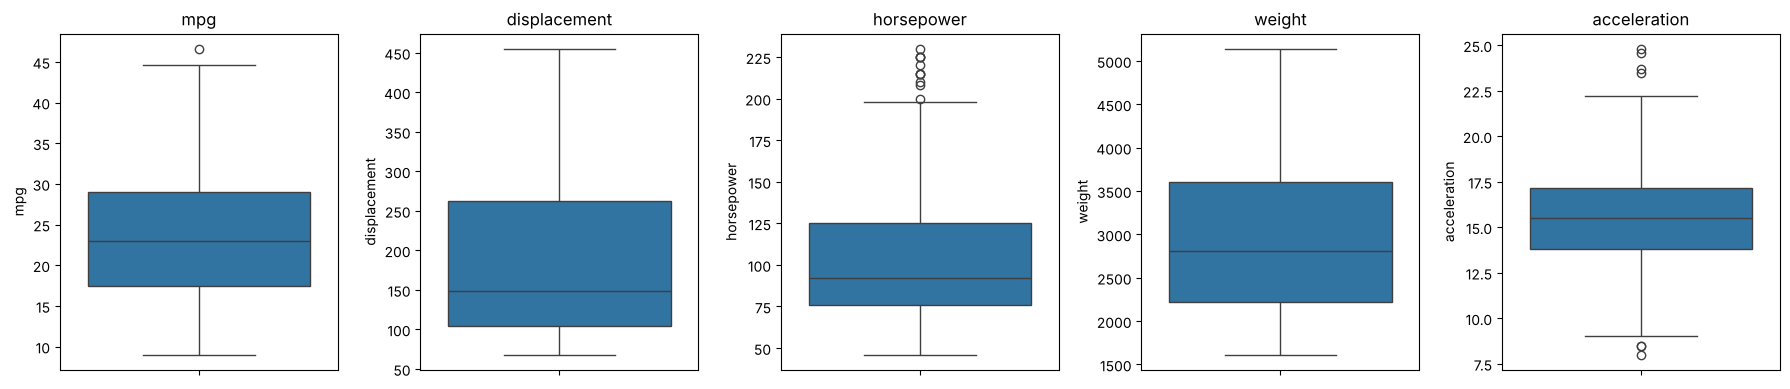

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [19]:
df_clean[df_clean['horsepower'] > 200][['car_name', 'cylinders', 'horsepower', 'weight', 'mpg']]

,car_name,cylinders,horsepower,weight,mpg
6,chevrolet impala,8,220.0,4354,14.0
7,plymouth fury iii,8,215.0,4312,14.0
8,pontiac catalina,8,225.0,4425,14.0
13,buick estate wagon (sw),8,225.0,3086,14.0
25,ford f250,8,215.0,4615,10.0
27,dodge d200,8,210.0,4382,11.0
67,mercury marquis,8,208.0,4633,11.0
94,chrysler new yorker brougham,8,215.0,4735,13.0
95,buick electra 225 custom,8,225.0,4951,12.0
116,pontiac grand prix,8,230.0,4278,16.0


The outliers are **real cars**, not data errors. For example, the high-horsepower cars are big 8-cylinder cars from the early 1970s, and a few small cars have very high acceleration times. Removing them would remove genuine information about powerful or unusual cars, so I **keep all outliers**.

### Step 7: Final check and save the cleaned data

In [20]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   car_name      398 non-null    str    
 9   brand         398 non-null    object 
dtypes: float64(4), int64(3), object(1), str(2)
memory usage: 31.2+ KB


In [21]:
print('Total missing values:', df_clean.isnull().sum().sum())
print('Shape:', df_clean.shape)
df_clean.head()

Total missing values: 0
Shape: (398, 10)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,brand
0,18.0,8,307.0,130.0,3504,12.0,70,USA,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,70,USA,buick skylark 320,buick
2,18.0,8,318.0,150.0,3436,11.0,70,USA,plymouth satellite,plymouth
3,16.0,8,304.0,150.0,3433,12.0,70,USA,amc rebel sst,amc
4,17.0,8,302.0,140.0,3449,10.5,70,USA,ford torino,ford


In [22]:
df_clean.to_csv('auto_mpg_clean.csv', index=False)
print('Saved auto_mpg_clean.csv')

Saved auto_mpg_clean.csv


### Data quality summary (for the client)

| # | Problem found | Rows affected | How I handled it |
|---|---|---|---|
| 1 | `horsepower` stored as text because of `?` symbols | 6 | Converted `?` to missing values and changed the column to numbers |
| 2 | Missing `horsepower` values | 6 (1.5%) | Filled with the median horsepower of cars with the same number of cylinders |
| 3 | Duplicate rows | 0 | No action needed; two same-name cars in the same year are different versions |
| 4 | `origin` stored as codes 1/2/3 | All | Replaced with USA / Europe / Japan |
| 5 | Brand names misspelled or written in different ways | 17 | Created a new `brand` column and fixed 9 different spellings |
| 6 | Outliers in horsepower, acceleration and mpg | A few | Checked; all are real cars, so they were kept |

**Result:** 398 cars, 10 columns, no missing values, correct data types. The cleaned data is saved as `auto_mpg_clean.csv`.

**Next step:** Phase 4, exploratory data analysis.